# 18. Euclidean Spaces

*A visual and computational introduction to the language that leads from multivariable calculus to differential geometry.*

This notebook follows the **section structure of Chapter 1, “Euclidean Spaces,”** in Loring W. Tu, *An Introduction to Manifolds* (2nd ed.). It is an explanatory companion, not a transcription. Exercises are original paraphrases and adaptations inspired by the chapter; consult Tu for the original statements and proofs.

## Why this chapter matters

Euclidean space $\mathbb{R}^n$ is the model local setting for smooth manifolds. We use its familiar coordinates to develop ideas that later make sense without a preferred coordinate system:

- smooth functions and Taylor approximation;
- tangent vectors as directional derivatives, hence as **derivations** on functions;
- alternating multilinear forms and the wedge product;
- differential forms and the exterior derivative;
- a unified language for gradient, curl, divergence, and integral theorems.

**Visualization-first approach:** most of the notebook uses geometric pictures and worked mathematical examples. Code appears only where a picture or a numerical check adds something useful. Each code cell is preceded by a statement of what it demonstrates.

# §1. Smooth Functions on a Euclidean Space

A function on an open set $U\subseteq\mathbb{R}^n$ is smooth, or $C^\infty$, if all partial derivatives of every finite order exist and are continuous. Smoothness is stronger than continuity or differentiability a fixed number of times.

## 1.1. $C^\infty$ Versus Analytic Functions

A real-analytic function agrees locally with its Taylor series. Every analytic function is smooth, but the converse fails.

A standard example is the *flat function*
$$
f(x)=\begin{cases}
e^{-1/x^2},&x>0,\\
0,&x\leq 0.
\end{cases}
$$
It is smooth at $0$ and every derivative there vanishes, but its Taylor series at $0$ is the zero series, which does not recover $f$ for $x>0$.

### Visual intuition

The graph becomes extraordinarily flat near the origin. A finite-resolution plot cannot prove smoothness, but it helps explain why numerical inspection alone cannot distinguish this function from the zero function near $0$.

**What the code below demonstrates:** it compares the flat function with the zero function near the origin, and shows why plotting the function itself is not enough to establish analyticity.

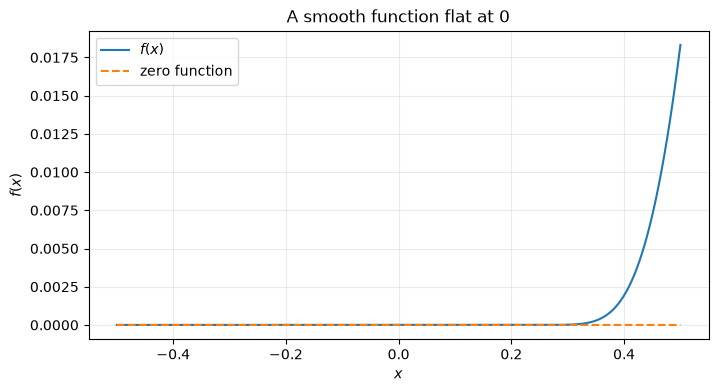

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-0.5, 0.5, 2001)
f = np.zeros_like(x)
positive = x > 0
f[positive] = np.exp(-1 / x[positive]**2)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, f, label=r"$f(x)$")
ax.plot(x, np.zeros_like(x), "--", label="zero function")
ax.set_title(r"A smooth function flat at $0$")
ax.set_xlabel("$x$")
ax.set_ylabel("$f(x)$")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 1.2. Taylor’s Theorem with Remainder

Near a point $p$, a smooth function can be approximated by its Taylor polynomial. The first-order approximation is
$$
f(x)=f(p)+\sum_{i=1}^n (x^i-p^i)g_i(x),
$$
where the smooth functions $g_i$ satisfy
$$
g_i(p)=\frac{\partial f}{\partial x^i}(p).
$$
In ordinary language: the difference between $f(x)$ and $f(p)$ is controlled by the displacement from $p$, with coefficients related to derivatives.

A set $U$ is **star-shaped with respect to** $p\in U$ if the line segment from $p$ to every point of $U$ stays inside $U$. Open balls are star-shaped about their centers, making them natural neighborhoods for local calculus.

### Exercises (inspired by §1)
1. Explain why $x\mapsto x^{1/3}$ is continuous at $0$ but not differentiable there.
2. For $g(x)=\int_0^x t^{1/3}\,dt$, determine the largest integer $k$ for which $g$ is $C^k$ at $0$.
3. Prove that $\tan:(-\pi/2,\pi/2)\to\mathbb{R}$ is a diffeomorphism by finding its inverse and checking smoothness.
4. Find an explicit linear diffeomorphism from any finite open interval $(a,b)$ to $(-1,1)$.
5. Give an example of a star-shaped set and a set that is not star-shaped with respect to a specified point.

# §2. Tangent Vectors in $\mathbb{R}^n$ as Derivations

In elementary calculus, a tangent vector at $p$ is drawn as an arrow based at $p$. Tu's key conceptual move is to regard it instead as an operation on smooth functions: it measures the instantaneous rate of change of a function in a specified direction.

## 2.1. The Directional Derivative

For $v=(v^1,\ldots,v^n)\in T_p\mathbb{R}^n$,
$$
D_vf(p)=\left.\frac{d}{dt}\right|_{t=0}f(p+tv)
=\sum_{i=1}^n v^i\frac{\partial f}{\partial x^i}(p).
$$
Thus the vector $v$ determines a linear functional on functions (or, more precisely, on their local behavior near $p$).

## 2.2. Germs of Functions

Two smooth functions defined near $p$ determine the same **germ at $p$** if they agree on some neighborhood of $p$. A derivative at $p$ depends only on this local behavior, not on how the function is defined far away.

For example, on $(-1,1)$, the functions $1/(1-x)$ and the convergent power series $1+x+x^2+\cdots$ represent the same germ at every point of that interval.

## 2.3. Derivations at a Point

A **derivation at $p$** is a linear map $D$ from germs of smooth functions at $p$ to $\mathbb{R}$ satisfying the Leibniz rule
$$
D(fg)=D(f)g(p)+f(p)D(g).
$$
Directional derivatives satisfy this rule. In Euclidean space, every derivation at $p$ arises uniquely from a tangent vector:
$$
T_p\mathbb{R}^n\cong \operatorname{Der}_p(C^\infty).
$$
This characterization generalizes to manifolds that do not come with a natural ambient Euclidean space.

## 2.4. Vector Fields

A smooth vector field assigns a tangent vector to every point:
$$
X=\sum_{i=1}^n a^i(x)\frac{\partial}{\partial x^i}.
$$
The coefficient functions $a^i$ vary smoothly with position. Geometrically, a vector field is a smoothly varying collection of arrows.

**What the code below demonstrates:** it visualizes two vector fields on the plane: a rotational field and a saddle-like field. These are pictures of vectors varying from point to point, rather than a single vector at one point.

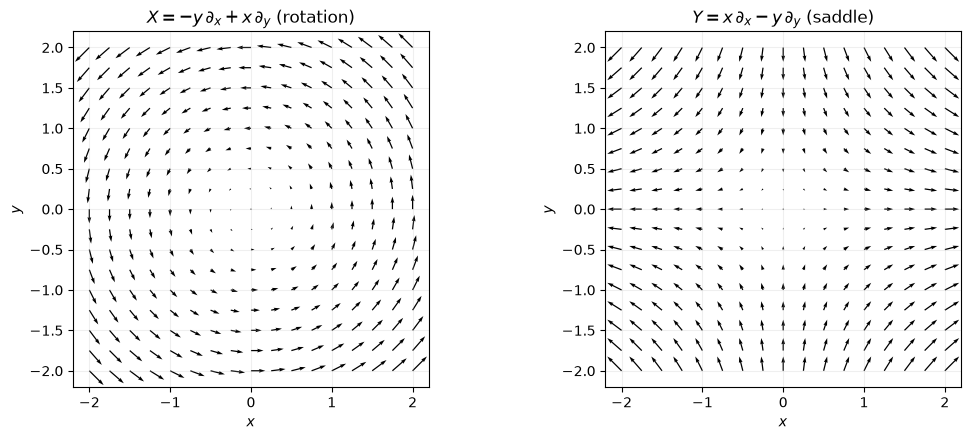

In [2]:
x = np.linspace(-2, 2, 17)
y = np.linspace(-2, 2, 17)
X, Y = np.meshgrid(x, y)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fields = [
    (-Y, X, r"$X=-y\,\partial_x+x\,\partial_y$ (rotation)"),
    (X, -Y, r"$Y=x\,\partial_x-y\,\partial_y$ (saddle)")
]
for ax, (U, V, title) in zip(axes, fields):
    ax.quiver(X, Y, U, V)
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 2.5. Vector Fields as Derivations

A vector field acts on a smooth function by differentiation:
$$
Xf=\sum_i a^i\frac{\partial f}{\partial x^i}.
$$
It obeys the Leibniz rule
$$
X(fg)=(Xf)g+f(Xg).
$$
This is the algebraic signature of differentiation. It is useful in differential geometry because it defines vector fields without relying on arrows embedded in a larger space.

### Exercises (inspired by §2)
1. Compute $D_vf(p)$ for $f(x,y)=x^2y+\sin y$, $p=(1,0)$, and $v=(2,-1)$.
2. Verify directly that $D_v(fg)(p)=D_vf(p)g(p)+f(p)D_vg(p)$ for two simple polynomial functions.
3. Explain why two functions that agree on a neighborhood of $p$ have the same directional derivative at $p$.
4. For $X=x\partial_x-y\partial_y$ and $f(x,y)=x^2+y^2$, compute $Xf$.
5. Show that a derivation sends every constant function to zero.

## 3. The Exterior Algebra of Multicovectors

The exterior algebra provides an algebraic language for describing oriented lengths, areas, volumes, and their higher-dimensional analogues. Its basic objects are **alternating multilinear functions**, also called *multicovectors*.

A linear functional measures a vector. An alternating bilinear function measures an oriented area determined by two vectors. An alternating trilinear function measures an oriented volume determined by three vectors.

The aim of this section is to construct these objects systematically, starting from linear functionals and multilinear algebra, and ending with the wedge product and a basis for spaces of alternating forms.

---

### 3.1. Dual Space

Let $V$ be a finite-dimensional real vector space. Its **dual space** is the vector space of linear functionals on $V$:

$$
V^*=\operatorname{Hom}(V,\mathbb R).
$$

Thus, a covector $\alpha\in V^*$ is a linear map

$$
\alpha:V\longrightarrow\mathbb R
$$

satisfying

$$
\alpha(av+bw)=a\alpha(v)+b\alpha(w)
$$

for all $v,w\in V$ and $a,b\in\mathbb R$.

Vectors and covectors are different kinds of objects: a vector belongs to $V$, while a covector belongs to $V^*$. A covector takes a vector as input and returns a scalar.

#### The dual basis

Let $(e_1,\ldots,e_n)$ be a basis of $V$. There is a unique dual basis $(\varepsilon^1,\ldots,\varepsilon^n)$ of $V^*$ satisfying

$$
\varepsilon^i(e_j)=\delta^i_j,
$$

where the Kronecker delta is

$$
\delta^i_j=
\begin{cases}
1,&i=j,\\
0,&i\neq j.
\end{cases}
$$

Every vector can be expressed as

$$
v=\sum_{i=1}^n v^i e_i.
$$

Applying a dual basis element gives

$$
\varepsilon^j(v)
=
\sum_{i=1}^n v^i\varepsilon^j(e_i)
=
v^j.
$$

Consequently, the dual basis extracts the coordinates of a vector.

#### Example: The dual of $\mathbb R^2$

Let $e_1=(1,0)$ and $e_2=(0,1)$. The dual basis consists of the coordinate projections

$$
\varepsilon^1(x,y)=x,
\qquad
\varepsilon^2(x,y)=y.
$$

For $v=(3,5)$,

$$
\varepsilon^1(v)=3,
\qquad
\varepsilon^2(v)=5.
$$

More generally, every covector on $\mathbb R^n$ has the form

$$
\alpha(x^1,\ldots,x^n)
=
a_1x^1+\cdots+a_nx^n.
$$

**Key fact:** If $\dim V=n$, then $\dim V^*=n$. In particular, the dual space has the same dimension as the original vector space, although its elements are linear functionals rather than vectors.

---

### 3.2. Permutations

A permutation of $\{1,\ldots,k\}$ is a bijection

$$
\sigma:\{1,\ldots,k\}\longrightarrow\{1,\ldots,k\}.
$$

The set of all such permutations is denoted by $S_k$. It contains $k!$ elements.

A permutation reorders a list of $k$ objects. For example, the permutation

$$
\sigma=(1\ 2\ 3)
$$

cyclically reorders three positions, sending $1\mapsto2$, $2\mapsto3$, and $3\mapsto1$.

A **transposition** exchanges two positions and leaves all the others fixed.

#### The sign of a permutation

Every permutation has a sign

$$
\operatorname{sgn}(\sigma)\in\{+1,-1\}.
$$

The sign is $+1$ for an even permutation and $-1$ for an odd permutation. Equivalently, the sign records the parity of the number of transpositions needed to express the permutation.

For example, exchanging two entries is a transposition, so it has sign $-1$.

A fundamental property is

$$
\operatorname{sgn}(\sigma\tau)
=
\operatorname{sgn}(\sigma)\operatorname{sgn}(\tau).
$$

In particular, the sign of a composition is the product of the signs.

#### Why permutations matter for geometry

The determinant changes sign when two rows or columns are exchanged. This is a consequence of the alternating nature of the determinant.

The same principle will appear when we define alternating multilinear functions: exchanging two input vectors reverses the sign of the output.

This sign records orientation. For instance, exchanging the two spanning vectors of a parallelogram reverses its orientation, even though its unsigned area stays the same.

---

### 3.3. Multilinear Functions

A function

$$
f:\underbrace{V\times\cdots\times V}_{k\text{ factors}}
\longrightarrow\mathbb R
$$

is **multilinear** if it is linear in each argument separately.

More explicitly, fixing all arguments except the $i$-th, we require

$$
\begin{aligned}
&f(v_1,\ldots,av_i+bw_i,\ldots,v_k)\\
&\quad =
a f(v_1,\ldots,v_i,\ldots,v_k)
+b f(v_1,\ldots,w_i,\ldots,v_k).
\end{aligned}
$$

This condition must hold for every argument position $i$.

A multilinear function need not be linear as a function on the product vector space $V^k$. Rather, it is linear in each input when the other inputs are held fixed.

#### Example 1: A bilinear function

On $\mathbb R^2$, define

$$
f((x_1,y_1),(x_2,y_2))
=
x_1x_2+y_1y_2.
$$

This is the standard Euclidean inner product. It is bilinear because it is linear in each of its two arguments.

For example,

$$
f(u+v,w)=f(u,w)+f(v,w).
$$

#### Example 2: The determinant

Define

$$
\omega(u,v)=\det
\begin{pmatrix}
u^1&v^1\\
u^2&v^2
\end{pmatrix}.
$$

For $u=(u^1,u^2)$ and $v=(v^1,v^2)$,

$$
\omega(u,v)=u^1v^2-u^2v^1.
$$

The determinant is bilinear in its two column vectors. It also changes sign when the columns are exchanged. Therefore, it is an example of an **alternating bilinear function**.

#### Alternating multilinear functions

A $k$-linear function $f$ is **alternating** if it vanishes whenever two of its arguments are equal:

$$
f(v_1,\ldots,v_k)=0
\quad\text{if }v_i=v_j
\text{ for some }i\neq j.
$$

An equivalent and particularly useful formulation is that exchanging two arguments reverses the sign:

$$
f(\ldots,v_i,\ldots,v_j,\ldots)
=
-f(\ldots,v_j,\ldots,v_i,\ldots).
$$

For alternating multilinear functions, the two formulations are equivalent over $\mathbb R$. Indeed, if $v_i=v_j$, exchanging those equal arguments leaves the input unchanged but changes the sign of the output, forcing the output to be zero.

We call an alternating $k$-linear function a **$k$-covector**. The vector space of these functions is denoted by

$$
\Lambda^k(V^*).
$$

The notation will become natural once we construct the wedge product.

---

### 3.4. The Permutation Action on Multilinear Functions

Permutations act on multilinear functions by rearranging their arguments.

Let $f:V^k\to\mathbb R$ be a $k$-linear function and $\sigma\in S_k$. Define

$$
(\sigma\cdot f)(v_1,\ldots,v_k)
=
f(v_{\sigma(1)},\ldots,v_{\sigma(k)}).
$$

This operation produces another $k$-linear function.

For example, if $k=2$ and $\tau$ exchanges the two positions, then

$$
(\tau\cdot f)(v_1,v_2)=f(v_2,v_1).
$$

This allows us to distinguish symmetric and antisymmetric behavior.

A function is **symmetric** if every permutation leaves it unchanged:

$$
\sigma\cdot f=f
\qquad\text{for all }\sigma\in S_k.
$$

A function is **alternating** if every permutation acts by its sign:

$$
\sigma\cdot f
=
\operatorname{sgn}(\sigma)f.
$$

In other words,

$$
f(v_{\sigma(1)},\ldots,v_{\sigma(k)})
=
\operatorname{sgn}(\sigma)
f(v_1,\ldots,v_k).
$$

The alternating condition means that even permutations preserve the value, whereas odd permutations reverse its sign.

#### Example: Symmetric versus alternating bilinear functions

The Euclidean inner product satisfies

$$
\langle u,v\rangle=\langle v,u\rangle.
$$

It is symmetric.

The determinant satisfies

$$
\det(u,v)=-\det(v,u).
$$

It is alternating.

This distinction is fundamental: symmetric bilinear functions naturally describe inner products, while alternating multilinear functions naturally describe oriented areas and volumes.

---

### 3.5. The Symmetrizing and Alternating Operators

We can extract the symmetric or alternating part of a multilinear function by averaging over all permutations.

Let $f:V^k\to\mathbb R$ be $k$-linear.

Define the **symmetrizing operator** by

$$
S(f)
=
\frac{1}{k!}
\sum_{\sigma\in S_k}\sigma\cdot f.
$$

Thus,

$$
S(f)(v_1,\ldots,v_k)
=
\frac{1}{k!}
\sum_{\sigma\in S_k}
f(v_{\sigma(1)},\ldots,v_{\sigma(k)}).
$$

The result is symmetric: permuting its arguments merely rearranges the terms in the sum.

Similarly, define the **alternating operator** by

$$
A(f)
=
\sum_{\sigma\in S_k}
\operatorname{sgn}(\sigma)\,
\sigma\cdot f.
$$

Explicitly,

$$
A(f)(v_1,\ldots,v_k)
=
\sum_{\sigma\in S_k}
\operatorname{sgn}(\sigma)
f(v_{\sigma(1)},\ldots,v_{\sigma(k)}).
$$

The result is alternating. Unlike the symmetrizing operator, this definition does not divide by $k!$.

#### Example: Alternating a bilinear function

For a bilinear function $f:V\times V\to\mathbb R$, there are two permutations: the identity and the transposition. Hence

$$
S(f)(u,v)
=
\frac12\bigl(f(u,v)+f(v,u)\bigr),
$$

and

$$
A(f)(u,v)
=
f(u,v)-f(v,u).
$$

The alternating operator therefore extracts the antisymmetric part, up to a conventional factor of $2$.

For example, if $f(u,v)=u^1v^2$, then

$$
A(f)(u,v)=u^1v^2-u^2v^1.
$$

This is precisely the determinant on $\mathbb R^2$.

**Important distinction:** The alternating operator used here is the unnormalized sum. Some texts define a normalized alternation by dividing by $k!$. Keep this convention in mind when comparing formulas for the wedge product.

---

### 3.6. The Tensor Product

The tensor product combines multilinear functions into a function with more arguments.

Suppose

$$
f:V^k\longrightarrow\mathbb R,
\qquad
g:V^\ell\longrightarrow\mathbb R
$$

are multilinear functions. Their tensor product is the $(k+\ell)$-linear function defined by

$$
\begin{aligned}
&(f\otimes g)(v_1,\ldots,v_{k+\ell})\\
&\qquad =
f(v_1,\ldots,v_k)\,
g(v_{k+1},\ldots,v_{k+\ell}).
\end{aligned}
$$

The first $k$ arguments go into $f$, and the remaining $\ell$ arguments go into $g$. The outputs are multiplied.

The tensor product is multilinear, but it need not be alternating—even when both factors are alternating.

#### Example: Tensor product of two covectors

Let $\alpha,\beta\in V^*$. Their tensor product is the bilinear function

$$
(\alpha\otimes\beta)(u,v)=\alpha(u)\beta(v).
$$

Interchanging the inputs gives

$$
(\alpha\otimes\beta)(v,u)=\alpha(v)\beta(u),
$$

which need not equal either the original value or its negative.

Thus, the tensor product does not automatically impose symmetry or antisymmetry.

#### Associativity

The tensor product is associative in the natural sense:

$$
(f\otimes g)\otimes h
=
f\otimes(g\otimes h).
$$

Both sides evaluate to the product of the values of $f$, $g$, and $h$ on their respective groups of arguments.

This means that parentheses may be omitted when forming tensor products of several multilinear functions.

The next step is to turn this general multilinear construction into an alternating one.

---

### 3.7. The Wedge Product

The **wedge product**, also called the exterior product, combines alternating multilinear functions to produce another alternating multilinear function.

Let

$$
f\in\Lambda^k(V^*),
\qquad
g\in\Lambda^\ell(V^*).
$$

Using the unnormalized alternating operator from §3.5, define

$$
\boxed{
f\wedge g
=
\frac{1}{k!\,\ell!}A(f\otimes g).
}
$$

Equivalently,

$$
\begin{aligned}
&(f\wedge g)(v_1,\ldots,v_{k+\ell})\\
&=\frac{1}{k!\,\ell!}
\sum_{\sigma\in S_{k+\ell}}
\operatorname{sgn}(\sigma)\\
&\qquad\qquad\cdot
f(v_{\sigma(1)},\ldots,v_{\sigma(k)})
g(v_{\sigma(k+1)},\ldots,v_{\sigma(k+\ell)}).
\end{aligned}
$$

The factor $1/(k!\ell!)$ compensates for repetitions arising from permuting the arguments within the two alternating factors. The result is alternating in all $k+\ell$ arguments.

#### Example 1: The wedge product of two covectors

For $\alpha,\beta\in V^*$, both degrees are $1$, so

$$
\begin{aligned}
(\alpha\wedge\beta)(u,v)
&=A(\alpha\otimes\beta)(u,v)\\
&=\alpha(u)\beta(v)-\alpha(v)\beta(u).
\end{aligned}
$$

Consequently,

$$
\alpha\wedge\beta=-\beta\wedge\alpha.
$$

In particular,

$$
\alpha\wedge\alpha=0.
$$

#### Example 2: The coordinate covectors on $\mathbb R^2$

Let $\varepsilon^1(x,y)=x$ and $\varepsilon^2(x,y)=y$. Then

$$
(\varepsilon^1\wedge\varepsilon^2)(u,v)
=
u^1v^2-u^2v^1.
$$

The wedge product of the two coordinate covectors is therefore the determinant.

Its absolute value gives the area of the parallelogram spanned by $u$ and $v$, while its sign records the orientation.

#### The wedge product in coordinates

For covectors

$$
\alpha=\sum_i a_i\varepsilon^i,
\qquad
\beta=\sum_j b_j\varepsilon^j,
$$

bilinearity gives

$$
\alpha\wedge\beta
=
\sum_{i,j}a_i b_j\,
\varepsilon^i\wedge\varepsilon^j.
$$

Since $\varepsilon^i\wedge\varepsilon^i=0$, terms with repeated indices vanish. Terms with distinct indices can be reordered using the sign rule developed in the next subsection.

This is the algebraic mechanism that makes the wedge product useful for representing oriented areas and higher-dimensional volumes.

---

### 3.8. Anticommutativity of the Wedge Product

The wedge product obeys a graded version of anticommutativity. If $f$ has degree $k$ and $g$ has degree $\ell$, then

$$
\boxed{
f\wedge g=(-1)^{k\ell}g\wedge f.
}
$$

The sign depends on the product of the degrees, not merely on whether the two factors are different.

#### Why does the sign appear?

To exchange the two blocks of arguments, we must move each of the $k$ arguments associated with $f$ past each of the $\ell$ arguments associated with $g$.

This requires $k\ell$ pairwise exchanges. Each exchange contributes a factor of $-1$, so the total factor is

$$
(-1)^{k\ell}.
$$

#### Examples

**Two 1-covectors.** For $\alpha,\beta\in\Lambda^1(V^*)$,

$$
\alpha\wedge\beta=-\beta\wedge\alpha.
$$

**A 1-covector and a 2-covector.** For $\alpha\in\Lambda^1(V^*)$ and $\omega\in\Lambda^2(V^*)$,

$$
\alpha\wedge\omega
=
(-1)^{1\cdot2}\omega\wedge\alpha
=
\omega\wedge\alpha.
$$

Thus, a 1-covector commutes with a 2-covector under the wedge product.

**Two 2-covectors.** For $\omega,\eta\in\Lambda^2(V^*)$,

$$
\omega\wedge\eta
=
(-1)^{2\cdot2}\eta\wedge\omega
$$

**What the code below demonstrates:** it draws two vectors and their parallelogram, linking the determinant to signed area and hence to the geometric meaning of a 2-form.

In [ ]:
u = np.array([2.0, 0.5])
v = np.array([0.6, 1.5])
origin = np.zeros(2)
corners = np.array([origin, u, u + v, v])

fig, ax = plt.subplots(figsize=(6, 5))
ax.fill(corners[:, 0], corners[:, 1], alpha=0.25, label="parallelogram")
ax.plot(*np.vstack([corners, corners[0]]).T, linewidth=2)
ax.quiver(0, 0, u[0], u[1], angles="xy", scale_units="xy", scale=1, label="$u$")
ax.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1, label="$v$")
ax.text(u[0], u[1], "$u$")
ax.text(v[0], v[1], "$v$")
signed_area = np.linalg.det(np.column_stack([u, v]))
ax.set_title(f"Signed area = det[u v] = {signed_area:.2f}")
ax.set_aspect("equal")
ax.set_xlim(-0.2, 3.0)
ax.set_ylim(-0.2, 2.5)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

### Exercises (inspired by §3)
1. Evaluate $(dx\wedge dy)(u,v)$ for $u=(1,2)$ and $v=(3,4)$.
2. Explain geometrically why $dx\wedge dx=0$.
3. Show that swapping two arguments of an alternating 2-form changes its sign.
4. How many independent basis elements are there in $\Lambda^2(\mathbb{R}^4)^*$? In $\Lambda^3(\mathbb{R}^4)^*$?
5. Expand $(dx+dy)\wedge(dx-dy)$.

# §4. Differential Forms on $\mathbb{R}^n$

A differential $k$-form assigns an alternating $k$-covector to each point, smoothly. Functions are 0-forms, differential 1-forms measure infinitesimal line-oriented quantities, 2-forms measure oriented surface quantities, and top-degree forms can be integrated over regions of full dimension.

## 4.1. Differential 1-Forms and the Differential of a Function

A 1-form has the local expression
$$
\omega=\sum_i a_i(x)\,dx^i.
$$
For a smooth function $f$, its differential is
$$
df=\sum_i\frac{\partial f}{\partial x^i}\,dx^i.
$$
It acts on a tangent vector by $df(v)=D_vf$. Under the Euclidean inner product, the coefficients of $df$ correspond to the gradient, but the 1-form $df$ is conceptually a covector.

## 4.2. Differential $k$-Forms

A $k$-form is a smooth combination of wedge products of $k$ coordinate covectors. On $\mathbb{R}^3$:
- 0-forms: $f(x,y,z)$;
- 1-forms: $P\,dx+Q\,dy+R\,dz$;
- 2-forms: $A\,dy\wedge dz+B\,dz\wedge dx+C\,dx\wedge dy$;
- 3-forms: $g\,dx\wedge dy\wedge dz$.

The degrees are not just labels: they indicate the dimension of the oriented object on which the form naturally integrates.

## 4.3. Differential Forms as Multilinear Functions on Vector Fields

A $k$-form takes $k$ vector fields as inputs and returns a smooth function. A 1-form measures a vector field; a 2-form measures pairs of vectors; a 3-form measures triples.

## 4.4. The Exterior Derivative

The exterior derivative maps $k$-forms to $(k+1)$-forms:
$$
d:\Omega^k(\mathbb{R}^n)\longrightarrow\Omega^{k+1}(\mathbb{R}^n).
$$
It generalizes the differential of a function and satisfies the graded product rule. Its defining structural identity is
$$
d^2=0.
$$
Thus every exact form is closed: if $\omega=d\eta$, then $d\omega=0$.

For a 1-form $\omega=P\,dx+Q\,dy+R\,dz$,
$$
d\omega=(R_y-Q_z)\,dy\wedge dz
+(P_z-R_x)\,dz\wedge dx
+(Q_x-P_y)\,dx\wedge dy.
$$

For a 2-form $\eta=A\,dy\wedge dz+B\,dz\wedge dx+C\,dx\wedge dy$,
$$
d\eta=(A_x+B_y+C_z)\,dx\wedge dy\wedge dz.
$$

## 4.5. Closed Forms and Exact Forms

A form $\omega$ is **closed** if $d\omega=0$, and **exact** if $\omega=d\eta$ for some form $\eta$. Every exact form is closed because $d^2=0$, but a closed form need not be exact on a space with nontrivial topology.

This is one bridge between local calculus and global topology: whether a closed form is exact can depend on the domain, not just on the formula.

**What the code below demonstrates:** it computes the exterior derivative of a 1-form and checks the identity $d(d f)=0$ symbolically for a smooth function.

In [3]:
import sympy as sp

x, y, z = sp.symbols("x y z")
f = x**2*y + sp.sin(z)
P = x*y
Q = x**2 + z
R = y*z

# For omega = P dx + Q dy + R dz, the coefficients of d(omega)
# in the basis (dy∧dz, dz∧dx, dx∧dy) are:
domega = (
    sp.diff(R, y) - sp.diff(Q, z),
    sp.diff(P, z) - sp.diff(R, x),
    sp.diff(Q, x) - sp.diff(P, y),
)
print("Coefficients of d(omega):", tuple(sp.simplify(a) for a in domega))

# df has coefficients f_x, f_y, f_z; compute d(df) using the same rule.
df_coeffs = (sp.diff(f, x), sp.diff(f, y), sp.diff(f, z))
ddf = (
    sp.diff(df_coeffs[2], y) - sp.diff(df_coeffs[1], z),
    sp.diff(df_coeffs[0], z) - sp.diff(df_coeffs[2], x),
    sp.diff(df_coeffs[1], x) - sp.diff(df_coeffs[0], y),
)
print("Coefficients of d(df):", tuple(sp.simplify(a) for a in ddf))

Coefficients of d(omega): (z - 1, 0, x)
Coefficients of d(df): (0, 0, 0)


## 4.6. Applications to Vector Calculus

This is the central application: the familiar vector-calculus operators are different degree-components of the single exterior derivative, once Euclidean space supplies a metric and an orientation to identify vectors and covectors.

### Gradient

For a scalar field $f$,
$$
df=f_x\,dx+f_y\,dy+f_z\,dz.
$$
With the Euclidean metric, its coefficient vector is the gradient
$$
\nabla f=(f_x,f_y,f_z).
$$

### Curl

Associate a vector field $F=(P,Q,R)$ with the 1-form
$$
F^\flat=P\,dx+Q\,dy+R\,dz.
$$
Then $d(F^\flat)$ encodes the curl:
$$
\nabla\times F=(R_y-Q_z,\;P_z-R_x,\;Q_x-P_y).
$$
More precisely, the 2-form $d(F^\flat)$ corresponds to the curl vector through the Euclidean Hodge star.

### Divergence

Associate $F$ with the 2-form
$$
\iota_F(dx\wedge dy\wedge dz)
=P\,dy\wedge dz+Q\,dz\wedge dx+R\,dx\wedge dy.
$$
Its exterior derivative is
$$
d(\iota_F\mathrm{vol})=(\nabla\cdot F)\,\mathrm{vol},
\qquad \nabla\cdot F=P_x+Q_y+R_z.
$$

### The vector-calculus identities become $d^2=0$

- $d(df)=0$ corresponds to $\nabla\times\nabla f=0$.
- $d(d(F^\flat))=0$ corresponds to $\nabla\cdot(\nabla\times F)=0$.

### Integral theorems

The general Stokes theorem is
$$
\int_M d\omega=\int_{\partial M}\omega.
$$
Its familiar special cases include the fundamental theorem of line integrals, Green's theorem, the classical Stokes theorem for surfaces in $\mathbb{R}^3$, and the divergence theorem. The common structure is **integrating a derivative over a region equals integrating the original object over its oriented boundary**.

### A worked example

Let $F=(-y/2,x/2,0)$. Then
$$
\nabla\times F=(0,0,1),\qquad \nabla\cdot F=0.
$$
The circulation around a positively oriented circle of radius $r$ is $\pi r^2$, equal to the flux of the curl through the disk. This is Stokes' theorem in a familiar form.

**What the code below demonstrates:** it plots the planar vector field $F=(-y/2,x/2)$ and numerically checks that its circulation around a circle matches the area enclosed, illustrating Green's/Stokes' theorem.

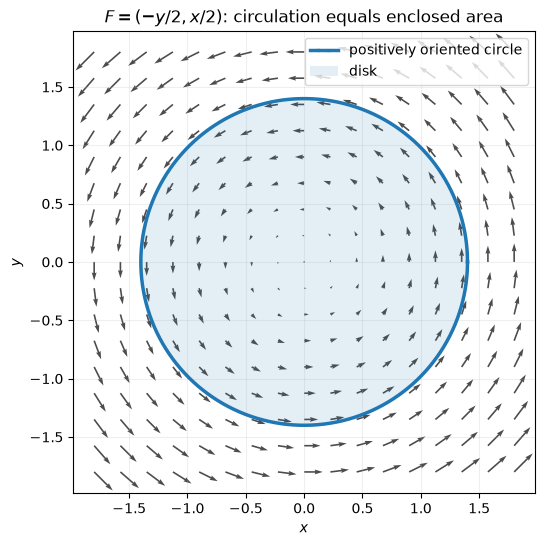

Circulation: 6.157522
Flux of curl through disk: 6.157522


In [4]:
theta = np.linspace(0, 2*np.pi, 500)
r = 1.4
xc, yc = r*np.cos(theta), r*np.sin(theta)

grid = np.linspace(-1.8, 1.8, 17)
X, Y = np.meshgrid(grid, grid)
U, V = -Y/2, X/2

fig, ax = plt.subplots(figsize=(6, 6))
ax.quiver(X, Y, U, V, alpha=0.7)
ax.plot(xc, yc, linewidth=2.5, label="positively oriented circle")
ax.fill(xc, yc, alpha=0.12, label="disk")
ax.set_aspect("equal")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title(r"$F=(-y/2,x/2)$: circulation equals enclosed area")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

# Exact values: integral F·dr around the circle = pi*r^2;
# integral curl(F)·n dA over the disk = area = pi*r^2.
circulation = np.pi * r**2
curl_flux = np.pi * r**2
print(f"Circulation: {circulation:.6f}")
print(f"Flux of curl through disk: {curl_flux:.6f}")

### Equation of continuity

Let $\rho(t,x)$ be a density and $J(t,x)$ its flux vector field. Conservation of mass/charge is expressed by
$$
\frac{\partial\rho}{\partial t}+\nabla\cdot J=0.
$$
In differential-form language, let $\mathrm{vol}$ be the Euclidean volume form and let $\iota_J\mathrm{vol}$ be the flux $(n-1)$-form. Then
$$
\frac{\partial}{\partial t}(\rho\,\mathrm{vol})+
d(\iota_J\mathrm{vol})=0.
$$
Integrating over a fixed region and applying Stokes gives
$$
\frac{d}{dt}\int_\Omega \rho\,\mathrm{vol}
=-\int_{\partial\Omega}\iota_J\mathrm{vol}.
$$
The amount of material inside the region changes by the negative of the outward flux through its boundary.

### Maxwell's equations in differential-form language

We now use the exterior derivative and differential forms to express Maxwell's equations. In spacetime, these equations have a particularly compact form. Let $F$ be the electromagnetic field 2-form, $J$ the electric-current 3-form, and $\star$ the Hodge star determined by the spacetime metric and orientation. In a common convention (with constants absorbed into the definitions), Maxwell's equations are
$$
dF=0,\qquad d\star F=J.
$$
The first equation combines the absence of magnetic monopoles with Faraday's law of induction; the second combines Gauss's law for electricity with the Ampère–Maxwell law. In SI-style conventions, source constants such as $\mu_0$ may appear on the right-hand side, and sign conventions depend on metric signature and the definition of $F$.

The structural point is that the homogeneous equations are $dF=0$, while the sourced equations use the Hodge dual and current form. Since $d^2=0$, applying $d$ to the sourced equation gives
$$
dJ=0,
$$
which is the differential-form expression of local charge conservation (with the convention above).

**Why the Hodge star appears:** the exterior derivative uses only smooth structure, while $\star$ also uses a metric and orientation. Curl/divergence and the inhomogeneous Maxwell equation require this extra metric information to identify complementary degrees of forms.

## 4.7. Convention on Subscripts and Superscripts

In differential geometry, coordinates are commonly written $x^1,\ldots,x^n$, while the coordinate 1-forms are written $dx^1,\ldots,dx^n$. Superscripts here label coordinates; they do not mean exponentiation. Coefficients of tangent vectors and coefficients of covectors transform differently under a coordinate change, which is why upper and lower indices are useful.

### Exercises (inspired by §4)
1. Compute $df$ for $f(x,y,z)=x^2y+yz^3$.
2. For $\omega=P\,dx+Q\,dy$ on $\mathbb{R}^2$, derive the condition for $d\omega=0$.
3. Compute $d\omega$ for $\omega=xy\,dx+xz\,dy+yz\,dz$.
4. Verify explicitly that $d^2f=0$ for a polynomial $f$ in three variables.
5. Find a vector field with zero divergence that is not identically zero.
6. Explain how Green's theorem is a special case of $\int_M d\omega=\int_{\partial M}\omega$.
7. Write the continuity equation in words and explain the sign of the flux term.
8. In the spacetime Maxwell equations, explain why $dF=0$ does not require a metric, whereas the Hodge star does.

# Review: the conceptual progression

1. **Smooth functions** are the objects we differentiate.
2. **Tangent vectors** can be understood as derivations acting on functions.
3. **Alternating covectors** measure oriented infinitesimal lengths, areas, and volumes.
4. **Differential forms** vary those covectors smoothly from point to point.
5. The **exterior derivative** unifies familiar differential operators and leads to Stokes' theorem.
6. **Differential forms** are the natural objects to integrate on manifolds.

## References

- Loring W. Tu, *An Introduction to Manifolds*, 2nd ed., Chapter 1, §§1–4. In particular, §4.6 is the source structure for the vector-calculus applications.
- Theodore Frankel, *The Geometry of Physics: An Introduction*, for the geometric formulation of electromagnetism using differential forms and the Hodge star.

**Note on exercises:** The exercises in this notebook are newly worded study questions inspired by the topics and progression of Tu's end-of-section problems; they are not reproduced verbatim from the book. For the exact original exercises, use the cited sections in Tu.